In [2]:
from scipy import signal
import h5py

In [4]:
data = h5py.File('iGluSnFR_Ras.mat')
import numpy as np
import matplotlib.pyplot as plt

In [5]:
a1 = data['iGluSnFR_Ras']['animal_1']
EMG = a1['EMG']
emg_amp = np.abs(EMG)
emg_score = np.mean(emg_amp, axis=0)

In [8]:
max_idx = np.argmax(emg_score)
raw_sig = EMG[:,max_idx]
t_emg = np.linspace(-1,1,2001)
print(raw_sig.shape)

(2001,)


In [9]:
freqs, psd =signal.welch(raw_sig, fs=1000)

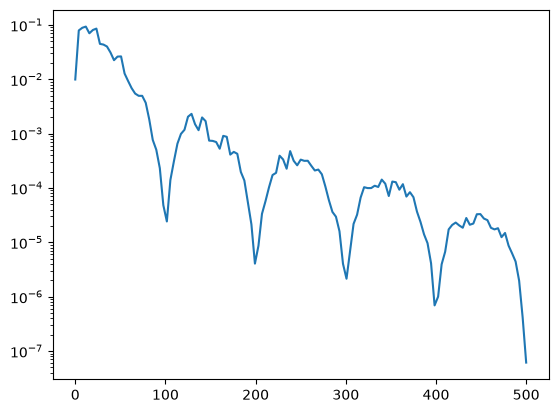

In [10]:
plt.semilogy(freqs,psd)

In [11]:
b, a = signal.butter(4, [50,300],btype='bandpass',fs=1000)

In [13]:
filtered_sig = signal.filtfilt(b,a,raw_sig)

In [14]:
freqs_f, psd_f =signal.welch(filtered_sig, fs=1000)

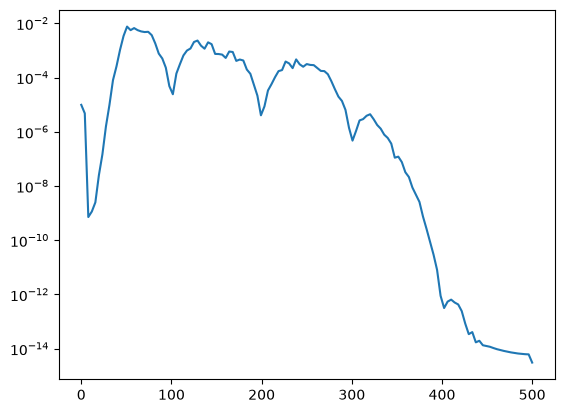

In [15]:
plt.semilogy(freqs_f,psd_f)

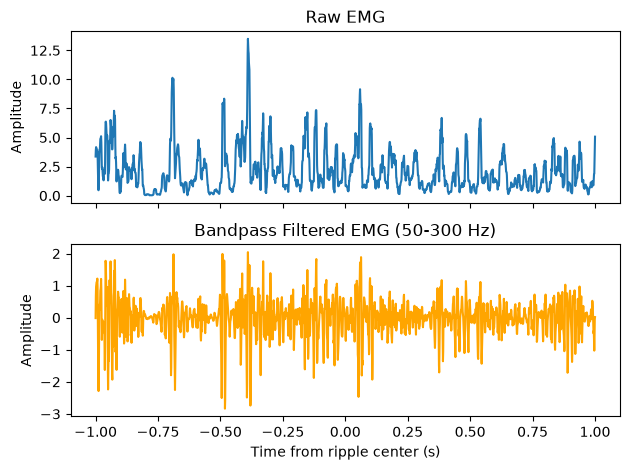

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

ax1.plot(t_emg, raw_sig)
ax1.set_title("Raw EMG")
ax1.set_ylabel("Amplitude")

ax2.plot(t_emg, filtered_sig, color='orange')
ax2.set_title("Bandpass Filtered EMG (50-300 Hz)")
ax2.set_xlabel("Time from ripple center (s)")
ax2.set_ylabel("Amplitude")

plt.tight_layout() 
plt.show()